In [ ]:
!pip install discopy==1.2.2

Local verification used preinstalled DisCoPy 1.2.2. Run this installation cell in Colab.


### SMSA 2.5 — Evaluation, coevaluation and snakes

**Source:** SMSA 7.8, 2026-11-05, §§2.5.18–2.5.22, equations (2.85)–(2.92). Local source: `smsa.pdf`. Source SHA-256: `6922b174be6719adbe0bfa0573cce44f0e5a7a54c4fafd5e43969c952813b8fe`.

**Translation conventions.** SMSA reads diagrams bottom to top. These unmodified native DisCoPy drawings read top to bottom: inputs are above outputs. Tensor factors retain their left-to-right order. `f >> g` means SMSA's $g\circ f$; `f @ g` means $f\otimes g$. The empty type represents the invisible unit wire. Coupons stand for the named SMSA maps even when SMSA uses a branching vertex. No custom functions or rewrite rules are introduced.

Checks print their computed objects and comparison results and continue when a mathematical comparison is false. A comparison in a concrete tensor model establishes only that model instance.

The SMSA ordering $\mathrm{ev}:V^*\otimes V\to\mathbb{F}$ and $\mathrm{coev}:\mathbb{F}\to V\otimes V^*$ corresponds to `V.l` in the native rigid API. This is a translation of dual notation, not an additional identification of the dual with $V$. Coevaluation has the unnormalized SMSA coefficients. Native bends omit the small direction arrows in SMSA.

In [1]:
from discopy import rigid, tensor
from discopy.drawing import Equation
V = rigid.Ty('V')
Vstar = V.l
ev = rigid.Cup(Vstar, V)
coev = rigid.Cap(V, Vstar)
snake_V = (coev @ rigid.Id(V)) >> (rigid.Id(V) @ ev)
snake_Vstar = (rigid.Id(Vstar) @ coev) >> (ev @ rigid.Id(Vstar))

V actual: V -> V ; expected: V -> V
Endomorphism of stated wire: True
Computed normal form: Id(V)
Expected: Id(V) ; equal: True
V* actual: V.l -> V.l ; expected: V.l -> V.l
Endomorphism of stated wire: True
Computed normal form: Id(V.l)
Expected: Id(V.l) ; equal: True


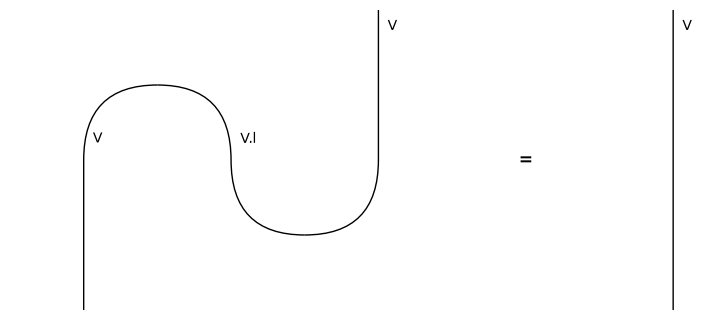

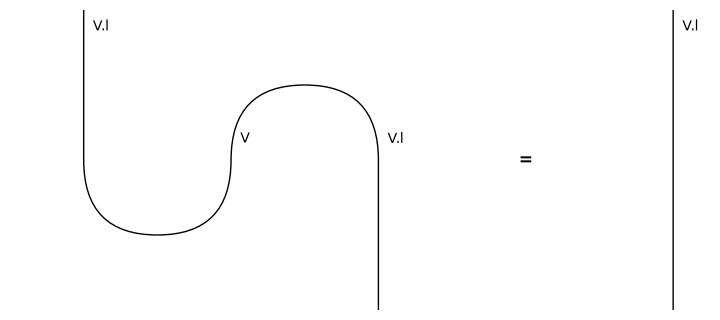

In [2]:
for name, snake, wire in [('V', snake_V, V), ('V*', snake_Vstar, Vstar)]:
    print(name, 'actual:', snake.dom, '->', snake.cod, '; expected:', wire, '->', wire)
    print('Endomorphism of stated wire:', snake.dom == wire and snake.cod == wire)
    print('Computed normal form:', snake.normal_form())
    print('Expected:', rigid.Id(wire), '; equal:', snake.normal_form() == rigid.Id(wire))
    Equation(snake, rigid.Id(wire)).draw(figsize=(7, 3))

In [3]:
F = tensor.Functor({V: 3}, {}, dom=rigid.Category(), dtype=int)
for name, snake, wire in [('V', snake_V, V), ('V*', snake_Vstar, Vstar)]:
    print(name, 'computed matrix:\n', F(snake).array)
    print('Expected identity:\n', F(rigid.Id(wire)).array)
    print('Exact model equality:', F(snake) == F(rigid.Id(wire)))

V computed matrix:
 [[1 0 0]
 [0 1 0]
 [0 0 1]]
Expected identity:
 [[1 0 0]
 [0 1 0]
 [0 0 1]]
Exact model equality: True
V* computed matrix:
 [[1 0 0]
 [0 1 0]
 [0 0 1]]
Expected identity:
 [[1 0 0]
 [0 1 0]
 [0 0 1]]
Exact model equality: True


`normal_form()` uses the rigid-category snake rewrite. The tensor functor supplies its own cups and caps; the three-dimensional calculation is a separate concrete interpretation.

**Opposite order (2.90).** Keeping the wire $V$ fixed, the opposite-order cup and cap use `V.r` instead of `V.l` in the rigid API. Both denote the dual vector space in the tensor interpretation; rigid syntax keeps these dual choices distinct.

(2.90) opposite cup boundary: V @ V.r -> rigid.Ty()
Opposite cap boundary: rigid.Ty() -> V.r @ V
Opposite snake normal form: Id(V) ; expected: Id(V)
Normal forms equal: True
Computed matrix:
 [[1 0 0]
 [0 1 0]
 [0 0 1]] 
Expected:
 [[1 0 0]
 [0 1 0]
 [0 0 1]]


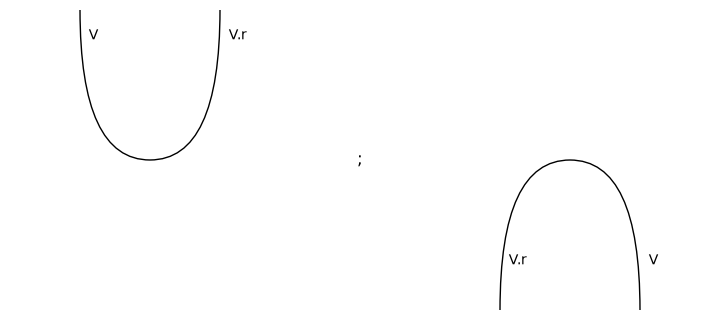

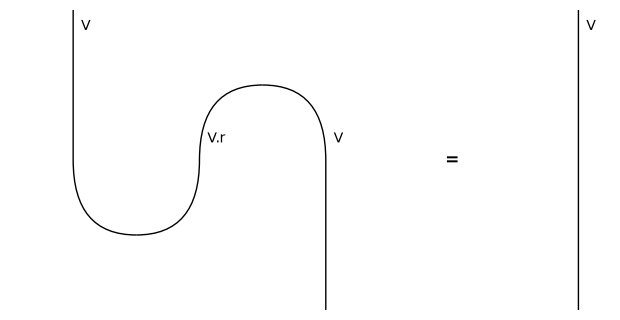

In [4]:
opposite_ev = rigid.Cup(V, V.r)
opposite_coev = rigid.Cap(V.r, V)
opposite_snake = (rigid.Id(V) @ opposite_coev) >> (opposite_ev @ rigid.Id(V))
Equation(opposite_ev, opposite_coev, symbol=';').draw(figsize=(7, 3))
Equation(opposite_snake, rigid.Id(V)).draw(figsize=(6, 3))
print('(2.90) opposite cup boundary:', opposite_ev.dom, '->', repr(opposite_ev.cod))
print('Opposite cap boundary:', repr(opposite_coev.dom), '->', opposite_coev.cod)
print('Opposite snake normal form:', opposite_snake.normal_form(), '; expected:', rigid.Id(V))
print('Normal forms equal:', opposite_snake.normal_form() == rigid.Id(V))
print('Computed matrix:\n', F(opposite_snake).array, '\nExpected:\n', F(rigid.Id(V)).array)

**The two bends in (2.92).** For finite-dimensional vector spaces, SMSA uses the same $V^*$ for the two orders. The native compact API makes this identification explicit. Its `transpose(left=True)` and `transpose()` construct the two bent diagrams. We compare their actual tensor values on an illustrative rectangular map; the equality below is a model evaluation.

(2.92) left bend column-matrix:
 [[1 3 5]
 [2 4 6]]
Right bend column-matrix:
 [[1 3 5]
 [2 4 6]]
Expected transpose:
 [[1 3 5]
 [2 4 6]]
Bends agree: True
Matches transpose: True


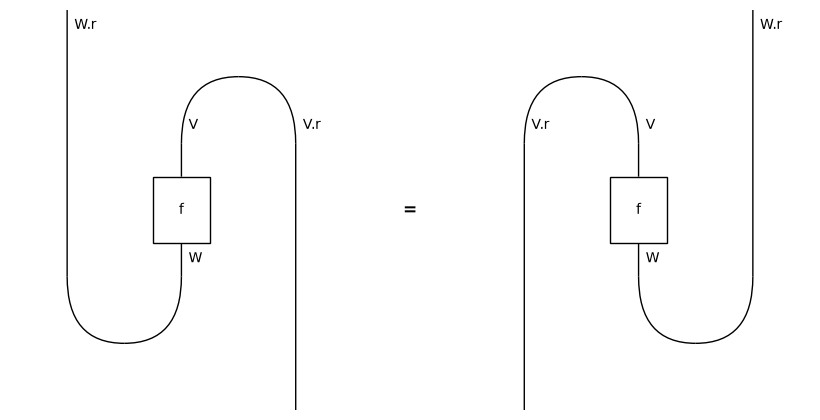

In [5]:
from discopy import compact
import numpy as np
Vc, Wc = map(compact.Ty, ['V', 'W'])
f = compact.Box('f', Vc, Wc)
M = np.array([[1, 2], [3, 4], [5, 6]])
T = tensor.Functor({Vc: 2, Wc: 3}, {f: M.T}, dom=compact.Category(), dtype=int)
left_bend = f.transpose(left=True)
right_bend = f.transpose()
Equation(left_bend, right_bend).draw(figsize=(8, 4))
print('(2.92) left bend column-matrix:\n', T(left_bend).array.T)
print('Right bend column-matrix:\n', T(right_bend).array.T)
print('Expected transpose:\n', M.T)
print('Bends agree:', T(left_bend) == T(right_bend))
print('Matches transpose:', np.array_equal(T(left_bend).array.T, M.T))

**Dual labels in the compact preview.** The compact module identifies left and right duals and may print the canonical label `V.r` even when the expression was written with `V.l`. The rigid snake cells retain the two dual types separately.